# MK Praktikum Unggulan Universitas Gunadarma
# Nama Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)  

---
### Overview Dataset

Dataset yang digunakan pada pertemuan ini adalah "Data Sensus Penghasilan". Data ini diambil dari database biro Sensus 1994 oleh Ronny Kohavi dan Barry Becker (Data Mining and Visualization, Silicon Graphics).

Data set ini berisikan beberapa kategori sebagai berikut:
* age
* sex
* race
* education
* marital-status
* workclass
* occupation
* relationship
* native-country
* hours-per-week
* capital-loss
* capital-gain
* fnlwgt

# Exploratory Data Analysis (EDA)

Pada praktikum ini, Anda akan melihat beberapa contoh Exploratory Data Analysis (EDA) pada data set sensus penghasilan.

* [Pengambilan Data](#1)
* [Univariate Analysis](#2)
* [Bivariate Analysis](#3)

# Instruksi Tugas Praktikum FIKTI dan FTI

<div class ="alert alert-info">
    <strong>Daftar Program Studi:</strong><br>
    <hr>
    <strong> Fakultas Ilmu Komputer dan Teknologi Informasi</strong><br>
    - Sistem Informasi (S1 - SI)<br>
    - Sistem Komputer (S1 - SK)<br>
    - Program Studi Manajemen Informatika (D3 - MI)<br>
    - Program Studi Teknik Komputer (D3 - TK)<br><br>
    <strong> Fakultas Teknologi Industri</strong><br>
    - Informatika (S1)<br>
    - Teknik Mesin (S1)<br>
    - Teknik Industri (S1)<br>
    - Teknik Elektro (S1)<br>
    - Agroteknologi (S1)<br>
</div>


1. Buat dan jelaskan univariate analysis untuk kategori <code>hours-per-week</code> dan <code>income</code>
2. Buat dan jelaskan bivariate analysis untuk hubungan antara <code>hours-per-week</code> dan <code>income</code>

<b> Notes: </b> Lakukan instruksi tugas diakhir file hands-on.

<a id="1"></a>

# 1. Pengambilan Data:

## 1.1 Import packages

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import warnings
warnings.filterwarnings("ignore")
from scipy.stats import ttest_ind, ttest_rel
from scipy import stats

## 1.2 Import data

In [2]:
data = pd.read_csv("https://gitlab.com/andreass.bayu/file-directory/-/raw/main/adult.csv")
data.head(10)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K
6,29,?,227026,HS-grad,9,Never-married,?,Unmarried,Black,Male,0,0,40,United-States,<=50K
7,63,Self-emp-not-inc,104626,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3103,0,32,United-States,>50K
8,24,Private,369667,Some-college,10,Never-married,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
9,55,Private,104996,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,10,United-States,<=50K


In [3]:
data.shape

(48842, 15)

In [4]:
data.dtypes

,0
age,int64
workclass,object
fnlwgt,int64
education,object
educational-num,int64
marital-status,object
occupation,object
relationship,object
race,object
gender,object


# 2. Exploratory Data Analysis (EDA)

## 2.1.Univariate analysis

<a id="2"></a>

- Jenis analisis statistik yang melibatkan satu variabel pada suatu waktu.
- Tujuannya adalah untuk memberikan gambaran tentang distribusi, statistik deskriptif, dan sifat-sifat lainnya dari variabel tunggal.
- Contoh analisis univariat termasuk histogram, box plot, ringkasan statistik seperti mean, median, dan modus, serta penghitungan frekuensi.

## 2.1.1 Kolom "Age"

### **i.	Distribusi**

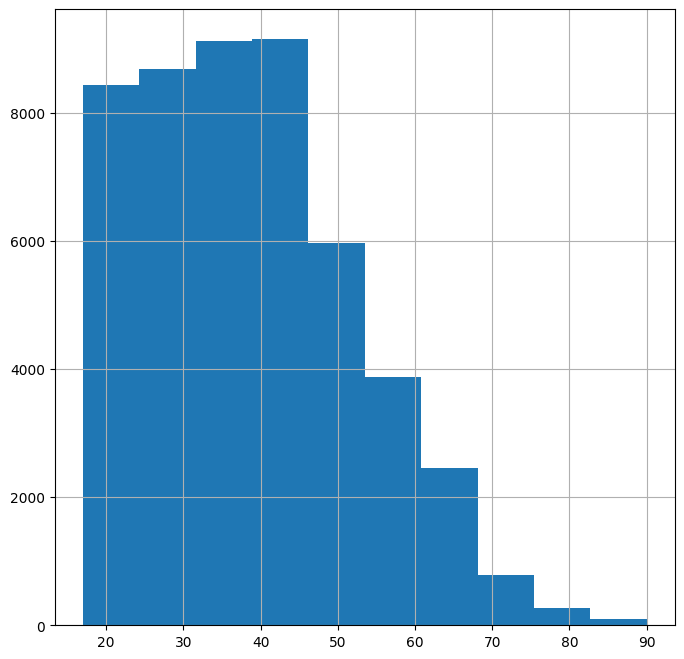

In [5]:
# Visualisasi HISTOGRAM
# Distribusi data dari kolom "Age"
data['age'].hist(figsize=(8,8))
plt.show()

In [6]:
data[data["age"] > 70].shape

(868, 15)

### **ii.	Deskripsi**
Histogram di atas menjelaskan bahwa:
*  Atribut "usia" tidak simetris.
*  Miring ke kanan (Tapi ini baik karena orang dewasa yang lebih muda mendapatkan upah bukan yang lebih tua).
*  Usia minimum dan maksimum orang adalah 17 dan 90 tahun.
*  Dataset ini memiliki lebih sedikit pengamatan (868) tentang usia orang setelah usia tertentu, yaitu 70 tahun.

## 2.1.2 Kolom "Income"

### **i. Distribusi**

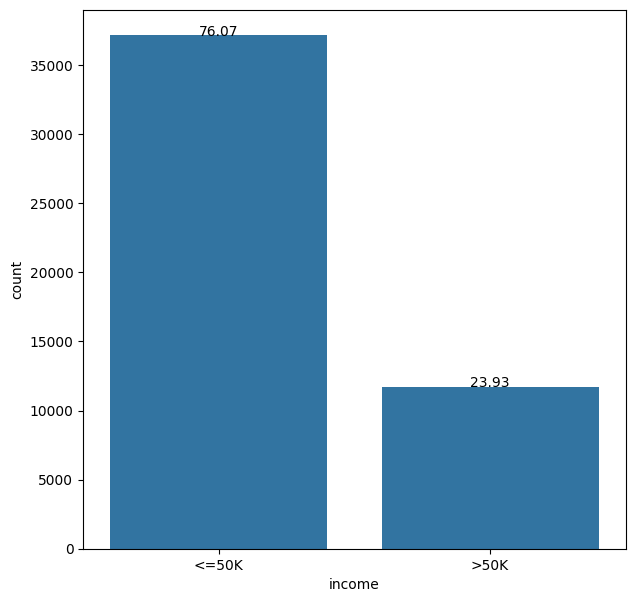

In [7]:
# Visualisasi BOXPLOT
# Distribusi data dari kolom "Income"
plt.figure(figsize=(7,7))
total = float(len(data) )

ax = sns.countplot(x="income", data=data)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x()+p.get_width()/2.,
            height + 3,
            '{:1.2f}'.format((height/total)*100),
            ha="center")
plt.show()

### **ii. Deskripsi**
Distribusi di atas menjelaskan bahwa **Dataset ini tidak seimbang, yaitu 23,93% di antaranya termasuk dalam kelompok pendapatan 1 (yang berpenghasilan lebih dari \\\$50K) dan 76% termasuk dalam kelompok pendapatan 0 (yang berpenghasilan kurang dari \\\$50K).**

<a id="3"></a>
# 2.2.Bivariate analysis

- Analisis bivariate melibatkan dua variabel pada saat yang sama dan mencoba untuk memahami hubungan antara keduanya.
- Analisis bivariate sering digunakan untuk menemukan korelasi atau asosiasi antara dua variabel, serta untuk memahami bagaimana variabel satu mempengaruhi variabel lainnya.
- Contoh analisis bivariate meliputi scatter plot, korelasi pearson, korelasi spearman, dan uji-t dua sampel.

## 2.2.1 Kolom "Age" & "Income" (Hubungan)

### i. **Boxplot**

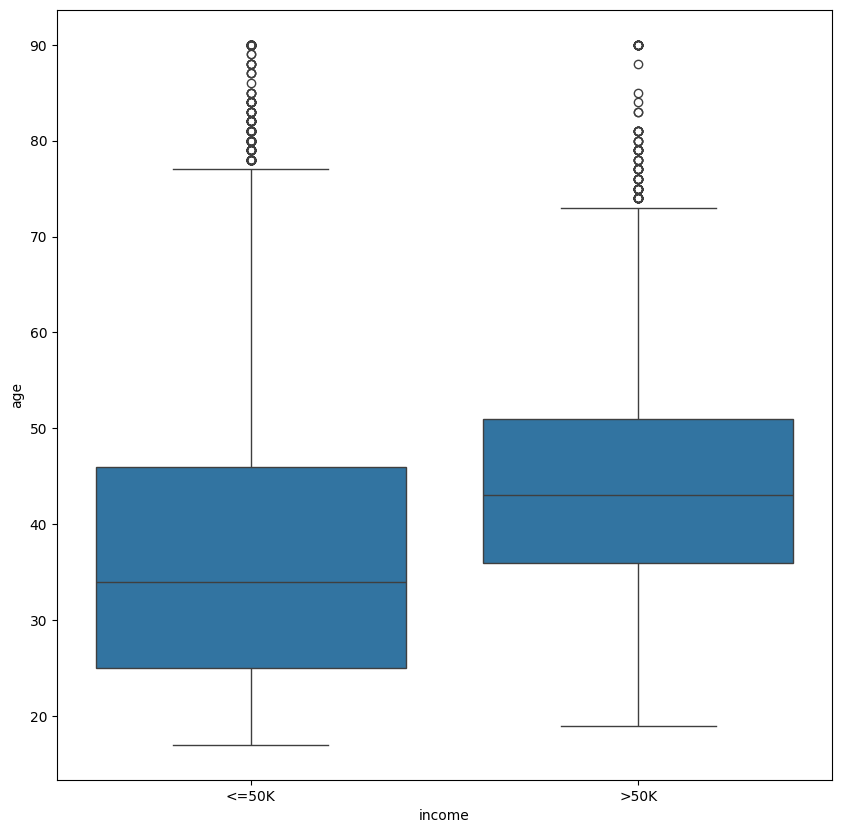

In [8]:
fig = plt.figure(figsize=(10,10))
sns.boxplot(x="income", y="age", data=data)
plt.show()

In [9]:
data[['income', 'age']].groupby(['income'], as_index=False).mean().sort_values(by='age', ascending=False)

,income,age
1,>50K,44.275178
0,<=50K,36.872184


### ii. Deskripsi
Bivariate boxplot di atas menjelaskan bahwa:
* Rata-rata "usia" untuk kelompok penghasilan (<= \\\$50K) adalah 36,8 tahun. Dan untuk kelompok penghasilan (> \\\$50K) adalah 44,2 tahun.
* Kelompok pendapatan (<=50K) memiliki median "usia" (34 tahun) lebih rendah daripada kelompok pendapatan (>50K) yang memiliki median "usia" (42 tahun).

### iii. Uji Hipotesis (untuk menguji hubungan antara kolom Age & Income)
**Two sampled T-test**:
Uji Independent Samples t Test atau 2-sample t-test membandingkan rata-rata dua kelompok independen untuk menentukan apakah ada bukti statistik bahwa rata-rata populasi terkait berbeda secara signifikan.

Contoh: Apakah ada hubungan antara usia dan pendapatan?

Tentukan null dan alternate hypothesis:

* Secara umum, null hypothesis akan menyatakan bahwa kedua populasi yang diuji tidak memiliki perbedaan yang signifikan secara statistik.
* Alternate hypothesis akan menyatakan bahwa ada perbedaan.

Dalam contoh ini kita dapat mengatakan bahwa:
*  Null Hypothesis: Tidak ada perbedaan rata-rata usia kelompok pendapatan > 50k dan kelompok pendapatan <= 50k.
*  Alternate Hypothesis: Ada perbedaan rata-rata usia kelompok pendapatan > 50k dan kelompok pendapatan <= 50k.

In [10]:
import random

data = data[(np.abs(stats.zscore(data["age"])) < 3)]

income_1 = data[data['income']=='<=50K']['age']
income_0 = data[data['income']=='>50K']['age']

income_0 = income_0.values.tolist()
income_0 = random.sample(income_0, 100)
income_1 = income_1.values.tolist()
income_1 = random.sample(income_1, 100)

In [11]:
from scipy.stats import ttest_ind
ttest,pval = ttest_ind(income_1,income_0,equal_var = False)
print("ttest",ttest)
print('p value',pval)


if pval <0.05:
    print("Kesimpulan: Null hypothesis ditolak")
else:
    print("Kesimpulan: Null hypothesis diterima")

ttest -2.7221951009127046
p value 0.00712297677410517
Kesimpulan: Null hypothesis ditolak


### iv. Kesimpulan

Menggunakan analisis statistik, dapat disimpulkan bahwa:
* Terdapat perbedaan yang signifikan pada rata-rata usia kelompok berpenghasilan > 50K dan kelompok berpenghasilan <= 50K. Hal Ini membuktikan bahwa usia memiliki peranan dalam membedakan kelompok pendapatan.

# Tugas
1. Buat dan jelaskan univariate analysis untuk kategori <code>hours-per-week</code> dan <code>income</code>
2. Buat dan jelaskan Bivariate analysis untuk hubungan antara <code>hours-per-week</code> dan <code>income</code>

<div class="alert alert-info">
    <strong>Catatan!</strong><br>
    - Pada bagian <code>#CODE HERE <...></code> digantikan dengan code python sesuai dengan perintah. <br>
    - Pada bagian <code># Ketik disini...</code> silakan diketikkan jawaban atas pertanyaan yang diberikan menggunakan Bahasa Indonesia.
    </div>

<div class ="alert alert-warning">
Silakan tambahkan cell code apabila diperlukan.  

</div>

## 1. Univariate analysis

## 1.1 Kolom "hours-per-week"

### **i.	Distribusi**

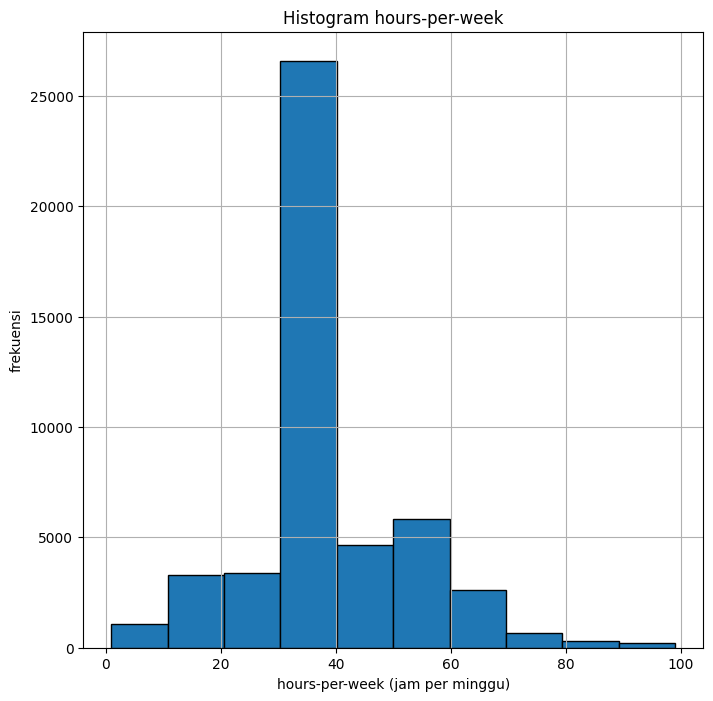

,hours-per-week
count,48656.000000
mean,40.468555
std,12.345652
min,1.000000
25%,40.000000
50%,40.000000
75%,45.000000
max,99.000000


In [12]:
# Visualisasi HISTOGRAM
# Distribusi data dari kolom "hours-per-week"
data['hours-per-week'].hist(figsize=(8, 8), bins=10, edgecolor='black')
plt.xlabel('hours-per-week (jam per minggu)')
plt.ylabel('frekuensi')
plt.title('Histogram hours-per-week')
plt.show()

# Statistik deskriptif kolom "hours-per-week"
data['hours-per-week'].describe()

### **ii. Deskripsi**


**Deskripsi - Univariate analysis kolom `hours-per-week`**

Berdasarkan histogram dan fungsi `describe()` di atas, distribusi jam kerja per minggu memiliki karakteristik:

* Rentang nilai **1 - 99 jam/minggu**, dengan mean **40.47**, median **40**, Q1 **40**, Q3 **45**, dan standar deviasi **12.35**.
* Distribusi **miring ke kanan (right-skewed, skewness ~ +0.25)**: ekor distribusi memanjang ke arah jam kerja yang tinggi, sedangkan sebagian besar data terpusat di kiri (30 - 50 jam).
* Nilai **modus ada di 40 jam/minggu**, yaitu **22.761 orang (46.78%)** bekerja tepat 40 jam/minggu - sesuai standar jam kerja mingguan.
* Kelompok jam kerja: **23.78%** bekerja kurang dari 40 jam, **29.44%** bekerja lebih dari 40 jam, dan hanya **7.90%** yang bekerja 60 jam/minggu atau lebih.
* Hampir separuh data (**54.64%**) berada pada bin 30.4 - 40.2 jam. Pada ekor kanan sangat sedikit, misalnya hanya **135 orang (0.28%)** yang bekerja 99 jam/minggu.

**Kesimpulan:** sebagian besar orang pada dataset ini bekerja dengan jam normal (30 - 50 jam/minggu), dengan sedikit pekerja ekstra (lebih dari 60 jam) yang membuat ekor kanan pada histogram.

## 1.2 Kolom "Income"

### **i.	Distribusi**

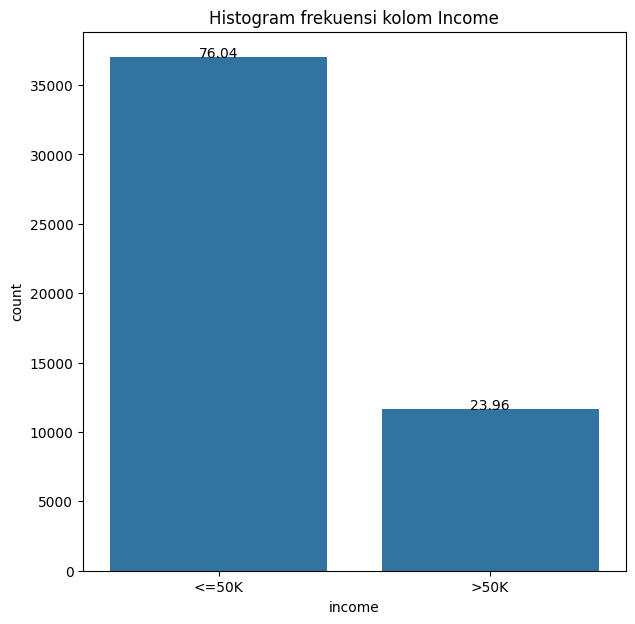

,count
income,
<=50K,36998
>50K,11658


In [13]:
# Visualisasi HISTOGRAM (frekuensi) kolom "Income"
# Kolom income bertipe kategorikal, sehingga histogram frekuensi dibuat dengan countplot
plt.figure(figsize=(7, 7))
total = float(len(data))

ax = sns.countplot(x="income", data=data)
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width() / 2.,
            height + 3,
            '{:1.2f}'.format((height / total) * 100),
            ha="center")
plt.title('Histogram frekuensi kolom Income')
plt.show()

# Jumlah data tiap kelompok income
data['income'].value_counts()

### **ii. Deskripsi**

**Deskripsi - Univariate analysis kolom `income`**

* Kolom `income` bertipe kategorikal dengan dua kelas, sehingga distribusinya divisualisasikan sebagai histogram frekuensi (countplot).
* Kelompok **`<=50K` berjumlah 36.998 orang (76.04%)**, sedangkan kelompok **`>50K` berjumlah 11.658 orang (23.96%)**.
* Artinya hampir 3 dari 4 orang pada dataset ini berpenghasilan kurang dari atau sama dengan \$50K, sehingga **dataset tidak seimbang (imbalanced)** - sekitar rasio 3:1.
* Karena dataset tidak seimbang, pada analisis/evaluasi model nanti akurasi saja tidak cukup (gunakan presisi, recall, F1-score, atau balanced accuracy), dan setiap perbandingan antar kelompok harus memperhatikan perbedaan jumlah sampel tersebut.

# 2. Bivariate analysis

## 2.1 Kolom "hours-per-week" & "income" (Hubungan)

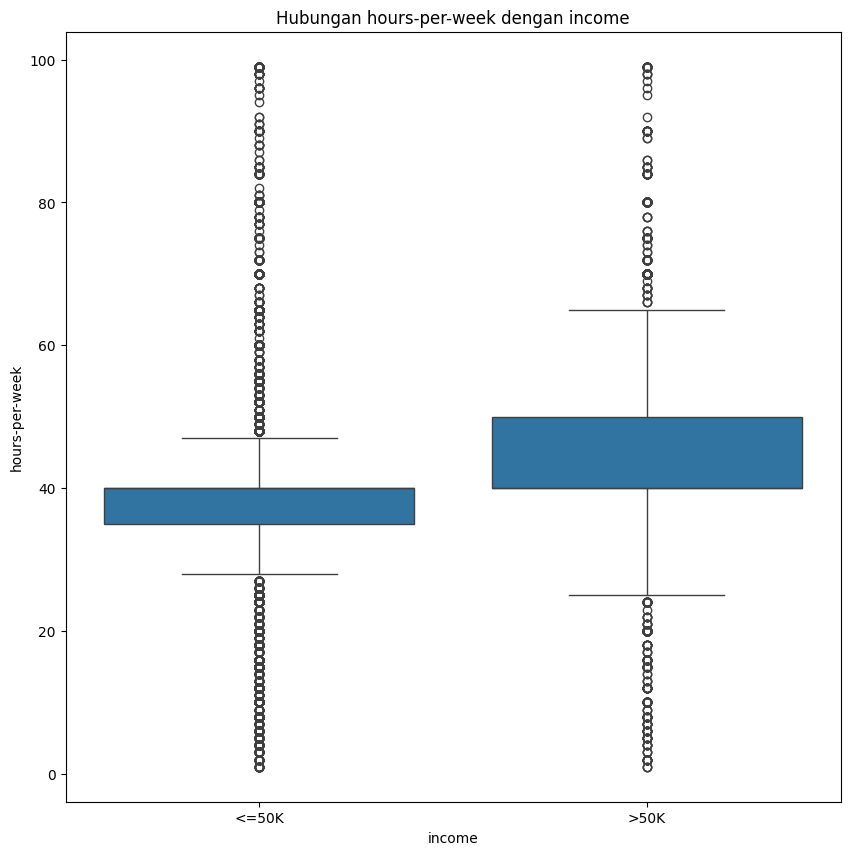

,count,mean,median,min,max,std
income,,,,,,
<=50K,36998,38.892967,40.0,1,99,12.306578
>50K,11658,45.468863,40.0,1,99,11.072539


In [14]:
# BOXPLOT: hubungan "hours-per-week" dengan "income"
fig = plt.figure(figsize=(10, 10))
sns.boxplot(x="income", y="hours-per-week", data=data)
plt.title('Hubungan hours-per-week dengan income')
plt.show()

# Ringkasan statistik jam kerja untuk tiap kelompok income
data.groupby('income')['hours-per-week'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])

### ii. Deskripsi

   

**Deskripsi - Bivariate analysis `hours-per-week` vs `income`**

* Boxplot menunjukkan kelompok `>50K` memiliki pusat distribusi yang lebih tinggi: **rata-rata 45.47 jam/minggu** dibanding **38.89 jam/minggu** pada kelompok `<=50K` (selisih **6.58 jam** atau sekitar **16.91%**).
* Median kedua kelompok sama-sama **40 jam**, namun kotak (IQR) kelompok `>50K` lebih tinggi, yaitu **Q1 - Q3 = 40 - 50 jam**, sedangkan kelompok `<=50K` hanya **35 - 40 jam**. Ini berarti 50% pendapatan tinggi berada pada rentang jam kerja yang lebih tinggi.
* Rentang whisker kelompok `<=50K` sekitar 27.5 - 47.5 jam dengan **31.37% outlier** (banyak yang bekerja di atas 47.5 jam tetap berpenghasilan <= \$50K), sedangkan kelompok `>50K` sekitar 25 - 65 jam dengan hanya **6.65% outlier**.
* Banyaknya outlier pada kelompok `<=50K` menunjukkan **jam kerja tinggi belum tentu berpenghasilan > \$50K** - masih ada faktor lain (pendidikan, jenis pekerjaan, wilayah, dll.) yang memengaruhi pendapatan.
* **Kesimpulan sementara:** terdapat hubungan positif antara lamanya jam kerja dan kelompok pendapatan, yaitu makin banyak jam kerja makin besar kecenderungan berada di kelompok `>50K`, tetapi hubungannya tidak sempurna (tumpang tindihnya cukup besar).

### iii. Uji Hipotesis (untuk menguji hubungan antara hours-per-week & income)
Dalam contoh ini kita dapat mengatakan bahwa:
*  Null Hypothesis: Tidak ada perbedaan rata-rata kelompok pendapatan > 50k dan kelompok pendapatan <= 50k.
*  Alternate Hypothesis: Ada perbedaan rata-rata kelompok pendapatan > 50k dan kelompok pendapatan <= 50k.

In [15]:
from scipy.stats import ttest_ind

# Kelompokkan jam kerja berdasarkan kelompok income
jam_50k = data[data['income'] == '<=50K']['hours-per-week']
jam_gt50k = data[data['income'] == '>50K']['hours-per-week']

# Two sample t-test (Welch, equal_var=False)
ttest, pval = ttest_ind(jam_50k, jam_gt50k, equal_var=False)
print("ttest", ttest)
print('p value', pval)

if pval < 0.05:
    print("Kesimpulan: Null hypothesis ditolak")
else:
    print("Kesimpulan: Null hypothesis diterima")

ttest -54.40388081041844
p value 0.0
Kesimpulan: Null hypothesis ditolak


### iv. Kesimpulan


**Kesimpulan**

* **Hipotesis:**
  * *Null hypothesis* (H0): tidak ada perbedaan rata-rata `hours-per-week` antara kelompok pendapatan `<=50K` dan `>50K`.
  * *Alternate hypothesis* (H1): ada perbedaan rata-rata `hours-per-week` antara kedua kelompok tersebut.
* **Hasil uji:** *two sample t-test* (Welch) memperoleh nilai **t ~ -54.40** dengan **p-value ~ 0** (jauh lebih kecil dari 0.05).
* **Keputusan:** **Null hypothesis ditolak**, karena p-value < 0.05.
* **Interpretasi:** rata-rata jam kerja kelompok `>50K` (**45.47 jam/minggu**) secara signifikan lebih tinggi daripada kelompok `<=50K` (**38.89 jam/minggu**). Lamanya waktu kerja memiliki peran yang signifikan dalam membedakan kelompok pendapatan - sejalan dengan hasil boxplot pada langkah sebelumnya.
* **Catatan:** uji-t hanya membuktikan adanya perbedaan rata-rata, bukan hubungan sebab-akibat; jumlah sampel yang sangat besar (masing-masing puluhan ribu) juga membuat perbedaan kecil pun bisa menjadi signifikan.

---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma


https://www.praktikum-hpc.gunadarma.ac.id/